# Costes del ejercicio: evidencia para fase 2 y defensa

## Resumen para la defensa

La matriz docente permite calcular el coste de las decisiones ya archivadas sin
volver a entrenar. Con FN = 5.000 €, FP = 200 €, TP = 300 € y TN = 0 €, recuperar
un fallo ahorra **4.700 €** y compensa **23,5 falsas alarmas adicionales**.

En las **mismas 5.600 filas de desarrollo / 190 positivos**, el RF con AVISO fijo
0,15 tiene un coste de escenario de **173.000 € (30.892,86 €/1.000 registros)**;
`always0`, 950.000 €; `always1`, 1.139.000 €. La diferencia de 777.000 € frente a
`always0` es hipotética y depende de la matriz, las acciones y esta cohorte.

Este notebook acompaña a [02_training_TEMPLATE.ipynb](02_training_TEMPLATE.ipynb).
La plantilla conserva su función de entrenamiento; este complemento no la
sustituye ni acredita una nueva evaluación independiente.

## Contexto y método

**Origen docente.** Cuerpo del foro aportado por el usuario, atribuido a **Aitor
Aretxaga Agirre**, **22/10/2026 a las 18:52** (zona horaria no indicada).
Transcripción local: `outputs/academic-inputs-20261023/forum-costs.txt`, SHA-256
`f292e1ff07785552ace80eaefaf0b7b2fd25ecfcb94aa45886c73affdbbaca32`.
No se consulta Moodle; esa copia puede faltar en otra máquina. Los cuatro
parámetros se leen del JSON versionado, contrastado con la copia aportada.
Se conservan como **parámetros oficiales del ejercicio según esa copia**;
la afirmación de que son finanzas reales no se ha auditado.

### Supuestos que condicionan la interpretación

- Cada fila representa una decisión binaria: actuar o no actuar. TP y FP incluyen
  su coste docente; no se añaden partidas inventadas ni se contabiliza dos veces
  el mismo fallo. El coste se expresa por registro, sin horizonte anual supuesto.
- Cohorte de desarrollo: **train 5.600 / 190 positivos**. La validación de
  **1.200 filas ya se reutilizó** en el proyecto y no constituye prueba final
  independiente. El **test de 1.200 permanece excluido**: no se abren sus datos,
  etiquetas ni resultados. Aquí tampoco se puntúa validación.
- Se leen exclusivamente JSON y tres CSV internos del ZIP económico versionado.
  No se cargan modelos, no hay fit, inferencia, calibración ni búsqueda de cortes.
  No se suman train, validación y test ni las distintas políticas entre sí.

### Separación inner / outer y selección archivada

El archivo original usa **3 folds outer**, cada uno con **3 folds inner**.
Para la política A del RF, el corte económico se eligió con predicciones OOF
inner de cada outer-train, con **recall inner mínimo 0,76**. Los desempates
archivados son coste, menos FN y corte más alto. El corte se aplicó al held-out
outer correspondiente. B y C usan cortes fijos 0,15 y 0,70.

El sello económico es de **23/10/2026, 09:43:34 UTC**, anterior al cálculo del
escenario suplementario, pero **posterior al conocimiento de los resultados
primarios**. Es un añadido económico posterior; no un preregistro prospectivo
del experimento original. El blindaje inner/outer evita elegir el corte de A
en su propio held-out; no deshace la exploración previa del desarrollo ni
convierte estos resultados en un test final.

Se compara el RF de referencia por el encargo docente, sin escoger un modelo por
su mínimo outer. No se dibuja una curva outer para elegir un nuevo corte.
Precision y recall de las políticas son diagnósticos de desarrollo.
El contrato operativo **AVISO 0,15 / CRÍTICA 0,70** se conserva.
`risk_threshold`, elegido para F2, es otro criterio; no es el corte económico
de A ni se reemplaza por los cálculos de este notebook.

## Datos y trazabilidad

Ejecutar desde la raíz del repositorio o desde `notebooks/`. `ROOT` se resuelve
relativamente. El código verifica hashes completos antes de calcular resultados.
Las imágenes quedan embebidas como PNG nativos; si se define
`COST_NOTEBOOK_OUTPUT_DIR`, también se guardan allí, sin escribir otros archivos
en el repositorio. Dependencias de análisis: Python 3.11+, Matplotlib e IPython;
para ejecutar y exportar: nbformat, nbclient, ipykernel y nbconvert.

In [1]:
from pathlib import Path
from collections import Counter
from fractions import Fraction
from html import escape
import csv
import hashlib
import io
import json
import math
import os
import platform
import zipfile
from importlib.metadata import version

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import HTML, Image, display

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents)
             if (p / 'docs/evidence/CG34_20261023/business-costs.json').is_file()
             and (p / 'notebooks').is_dir()), None)
assert ROOT is not None, 'Abra el notebook dentro del repositorio.'
EVIDENCE = ROOT / 'docs/evidence/CG34_20261023'
export_dir = os.environ.get('COST_NOTEBOOK_OUTPUT_DIR')
FIGURE_DIR = Path(export_dir).resolve() if export_dir else None
if FIGURE_DIR:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 14, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': '#202a35', 'axes.labelcolor': '#202a35',
    'xtick.color': '#202a35', 'ytick.color': '#202a35',
})

def table(headers, rows):
    header = ''.join(f'<th>{escape(str(x))}</th>' for x in headers)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(x))}</td>' for x in row)
                   + '</tr>' for row in rows)
    display(HTML('<div style="max-width:100%;overflow-x:auto">'
                 f'<table style="white-space:nowrap"><thead><tr>{header}</tr></thead>'
                 f'<tbody>{body}</tbody></table></div>'))

def es(value, decimals=0):
    return f'{value:,.{decimals}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def show_png(fig, name, description):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    png = buffer.getvalue()
    if FIGURE_DIR:
        (FIGURE_DIR / name).write_bytes(png)
    display(Image(data=png, format='png', width=960, alt=description))
    plt.close(fig)

print('Python', platform.python_version(), '| Matplotlib', version('matplotlib'))
print('Fuentes: docs/evidence/CG34_20261023; sin entrenamiento ni acceso al test.')

Python 3.11.9 | Matplotlib 3.11.2
Fuentes: docs/evidence/CG34_20261023; sin entrenamiento ni acceso al test.


### Verificar los archivos antes de usarlos

Los hashes fijan esta versión del complemento; un cambio de entrada detiene la
ejecución en lugar de mezclar evidencias. El manifiesto aporta pertenencia de
train y folds. Solo se usa su metadato de train; no se leen registros del test.

In [2]:
EXPECTED_SHA256 = {
    'business-costs.json': '28e1708bf9f5731cb3dc3efb4edf1ea79d7142ba009c17170c961501708cc706',
    'business-summary.json': 'd820c7c296297d4723e22bb1d03e369ae06399aef50a8c80aed94606a831f9f4',
    'business-evidence.zip': '922b1840aa6d09ee57120959cdd1f2de94ba1418d933bbc02abb7e8db49671c5',
    'business-archive.json': '3b6cf1fb1164a1b8c5ec7e16b6977141cfab4b6d8be6fa50ce825fab4d8f1a27',
    'business-seal.json': 'c477caa068d5e0e13a5393606a3462f4548305d79898364ed95d2f8bc5dd21af',
    'manifest.json': 'd881aa24d43a1f44e98956c37a4e88cacb21989a1fe0c205ed9e8d67aa72187b',
}
inputs = {}
for name, expected in EXPECTED_SHA256.items():
    payload = (EVIDENCE / name).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == expected, f'Hash distinto: {name}'
    inputs[name] = payload

config = json.loads(inputs['business-costs.json'])
summary = json.loads(inputs['business-summary.json'])
archive = json.loads(inputs['business-archive.json'])
seal = json.loads(inputs['business-seal.json'])
manifest = json.loads(inputs['manifest.json'])
costs = config['cost_eur']
assert costs == {'fn': 5000, 'fp': 200, 'tp': 300, 'tn': 0}
assert summary['config'] == config
assert summary['config_sha256'] == seal['config_sha256'] == EXPECTED_SHA256['business-costs.json']
assert summary['manifest_sha256'] == EXPECTED_SHA256['manifest.json']
assert archive['sha256'] == EXPECTED_SHA256['business-evidence.zip']
assert len(inputs['business-evidence.zip']) == archive['bytes']
assert seal['prior_primary_results_known'] and not seal['new_fits_authorized']
assert config['minimum_inner_recall'] == 0.76
assert config['fixed_policies'] == [0.15, 0.70] and not config['operational_change']
assert len(manifest['outer']) == 3
assert all(len(fold['inner']) == 3 for fold in manifest['outer'])
table(['Entrada verificada', 'SHA-256 completo'], EXPECTED_SHA256.items())

Entrada verificada,SHA-256 completo
business-costs.json,28e1708bf9f5731cb3dc3efb4edf1ea79d7142ba009c17170c961501708cc706
business-summary.json,d820c7c296297d4723e22bb1d03e369ae06399aef50a8c80aed94606a831f9f4
business-evidence.zip,922b1840aa6d09ee57120959cdd1f2de94ba1418d933bbc02abb7e8db49671c5
business-archive.json,3b6cf1fb1164a1b8c5ec7e16b6977141cfab4b6d8be6fa50ce825fab4d8f1a27
business-seal.json,c477caa068d5e0e13a5393606a3462f4548305d79898364ed95d2f8bc5dd21af
manifest.json,d881aa24d43a1f44e98956c37a4e88cacb21989a1fe0c205ed9e8d67aa72187b


### Leer únicamente tres miembros del ZIP

Se comprueban también los hashes de los miembros consumidos y la coincidencia
del resumen interno. No se extrae ni ejecuta código del ZIP. Las curvas de
desarrollo archivadas no se usan para proponer cortes.

In [3]:
MEMBERS = ('analysis/rf_reference-outer.csv',
           'analysis/always0-outer.csv', 'analysis/always1-outer.csv')
with zipfile.ZipFile(io.BytesIO(inputs['business-evidence.zip'])) as bundle:
    assert len(bundle.namelist()) == len(set(bundle.namelist())) == archive['files']
    index_bytes = bundle.read('index.json')
    assert hashlib.sha256(index_bytes).hexdigest() == '6c6eaf6add1d095b9260ad188522a585c7016f8ed6ed6da59b1ef3aadfe1662c'
    index = json.loads(index_bytes)
    members = {}
    for name in (*MEMBERS, 'analysis/business-summary.json'):
        payload = bundle.read(name)  # zipfile comprueba CRC del miembro leído.
        assert len(payload) == index[name]['bytes']
        assert hashlib.sha256(payload).hexdigest() == index[name]['sha256']
        members[name] = payload
    assert members['analysis/business-summary.json'] == inputs['business-summary.json']

def read_archived_rows(name):
    reader = csv.DictReader(io.StringIO(members[name].decode('utf-8')))
    assert reader.fieldnames == ['source_row_index', 'label', 'score', 'threshold', 'outer']
    rows = []
    for raw in reader:
        row = {key: int(raw[key]) for key in ('source_row_index', 'label', 'outer')}
        row.update({key: float(raw[key]) for key in ('score', 'threshold')})
        assert row['label'] in (0, 1) and row['outer'] in (0, 1, 2)
        assert all(math.isfinite(row[key]) and 0 <= row[key] <= 1
                   for key in ('score', 'threshold'))
        rows.append(row)
    return rows

archived_rows = {name: read_archived_rows(f'analysis/{name}-outer.csv')
                 for name in ('rf_reference', 'always0', 'always1')}
rf_rows = archived_rows['rf_reference']
print('Leídos: RF, always0, always1; resúmenes y miembros con hashes concordantes.')

Leídos: RF, always0, always1; resúmenes y miembros con hashes concordantes.


### Comprobar la misma cohorte y conservar los cortes archivados

Cada política se evalúa sobre los mismos identificadores, etiquetas y folds.
Los tres held-out outer son disjuntos y cubren train una vez. Los inner de
distintos outer-train se solapan: sus tamaños no se suman como otra cohorte.

In [4]:
N, P = 5600, 190
train_ids = set(manifest['membership']['train'])
assert len(train_ids) == N
identity = {(r['source_row_index'], r['label'], r['outer']) for r in rf_rows}
assert len(rf_rows) == len(identity) == N
assert {r['source_row_index'] for r in rf_rows} == train_ids
assert sum(r['label'] for r in rf_rows) == P
for rows in archived_rows.values():
    assert len(rows) == N
    assert len({r['source_row_index'] for r in rows}) == N
    assert {(r['source_row_index'], r['label'], r['outer']) for r in rows} == identity

fold_table = []
for decision in summary['models']['rf_reference']['folds']:
    fold_id = decision['outer']
    held = [r for r in rf_rows if r['outer'] == fold_id]
    fold = manifest['outer'][fold_id]
    held_ids = {r['source_row_index'] for r in held}
    fit_ids = set(fold['fit'])
    assert held_ids == set(fold['held'])
    assert not held_ids & fit_ids and held_ids | fit_ids == train_ids
    for inner in fold['inner']:
        assert not set(inner['fit']) & set(inner['held'])
        assert set(inner['fit']) | set(inner['held']) == fit_ids
    assert all(r['threshold'] == decision['threshold'] for r in held)
    assert decision['inner']['n'] == len(fit_ids)
    assert decision['inner']['recall'] >= config['minimum_inner_recall']
    fold_table.append([fold_id, len(held), sum(r['label'] for r in held),
                       len(fit_ids), f"{decision['threshold']:.9f}",
                       es(100 * decision['inner']['recall'], 2) + '%'])
table(['Outer', 'Filas held-out', 'Positivos held-out', 'Filas inner OOF',
       'Corte A archivado', 'Recall inner'], fold_table)

Outer,Filas held-out,Positivos held-out,Filas inner OOF,Corte A archivado,Recall inner
0,1867,63,3733,0.175119048,"91,34%"
1,1867,64,3733,0.157598796,"88,10%"
2,1866,63,3734,0.070416667,"90,55%"


## Resultados

### 1. Matriz docente y valor marginal

La clase positiva significa fallo. En este ejercicio, una alerta lleva a actuar:

| Realidad | Actuar: alerta positiva | No actuar: alerta negativa |
|---|---:|---:|
| Fallo | TP: 300 € | FN: 5.000 € |
| Sin fallo | FP: 200 € | TN: 0 € |

**C = 5.000·FN + 200·FP + 300·TP + 0·TN.** Con P positivos fijos,
TP = P − FN, de modo que **C = 300·P + 4.700·FN + 200·FP**.
Por eso el ahorro marginal de pasar un FN a TP es 5.000 − 300 = 4.700 €.
La razón bruta 5.000/200 = 25 omite el coste del TP y no es el intercambio
marginal. Para un FN recuperado y k nuevos FP: **ΔC = −4.700 + 200·k**.

In [5]:
marginal_recovery = costs['fn'] - costs['tp']
marginal_false_alarm = costs['fp'] - costs['tn']
break_even = Fraction(marginal_recovery, marginal_false_alarm)
gross_ratio = Fraction(costs['fn'], costs['fp'])
assert marginal_recovery == 4700 and break_even == Fraction(47, 2)
assert gross_ratio == 25
assert 23 * marginal_false_alarm - marginal_recovery == -100
assert 24 * marginal_false_alarm - marginal_recovery == 100
print(f'FN → TP: ahorro {es(marginal_recovery)} €; equilibrio: {float(break_even):g} FP.')
print('Con 23 FP extra aún se ahorran 100 €; con 24 FP extra se gastan 100 € más.')

FN → TP: ahorro 4.700 €; equilibrio: 23.5 FP.
Con 23 FP extra aún se ahorran 100 €; con 24 FP extra se gastan 100 € más.


### Figura 1. ¿Cuándo deja de compensar recuperar un fallo?

Escenario analítico **hipotético**, independiente del RF: se recupera exactamente
un FN y aparecen k FP adicionales (anteriores TN). La línea une valores de la
fórmula; los recuentos reales son enteros. No representa observaciones ni
garantiza que un cambio de umbral produzca ese intercambio.

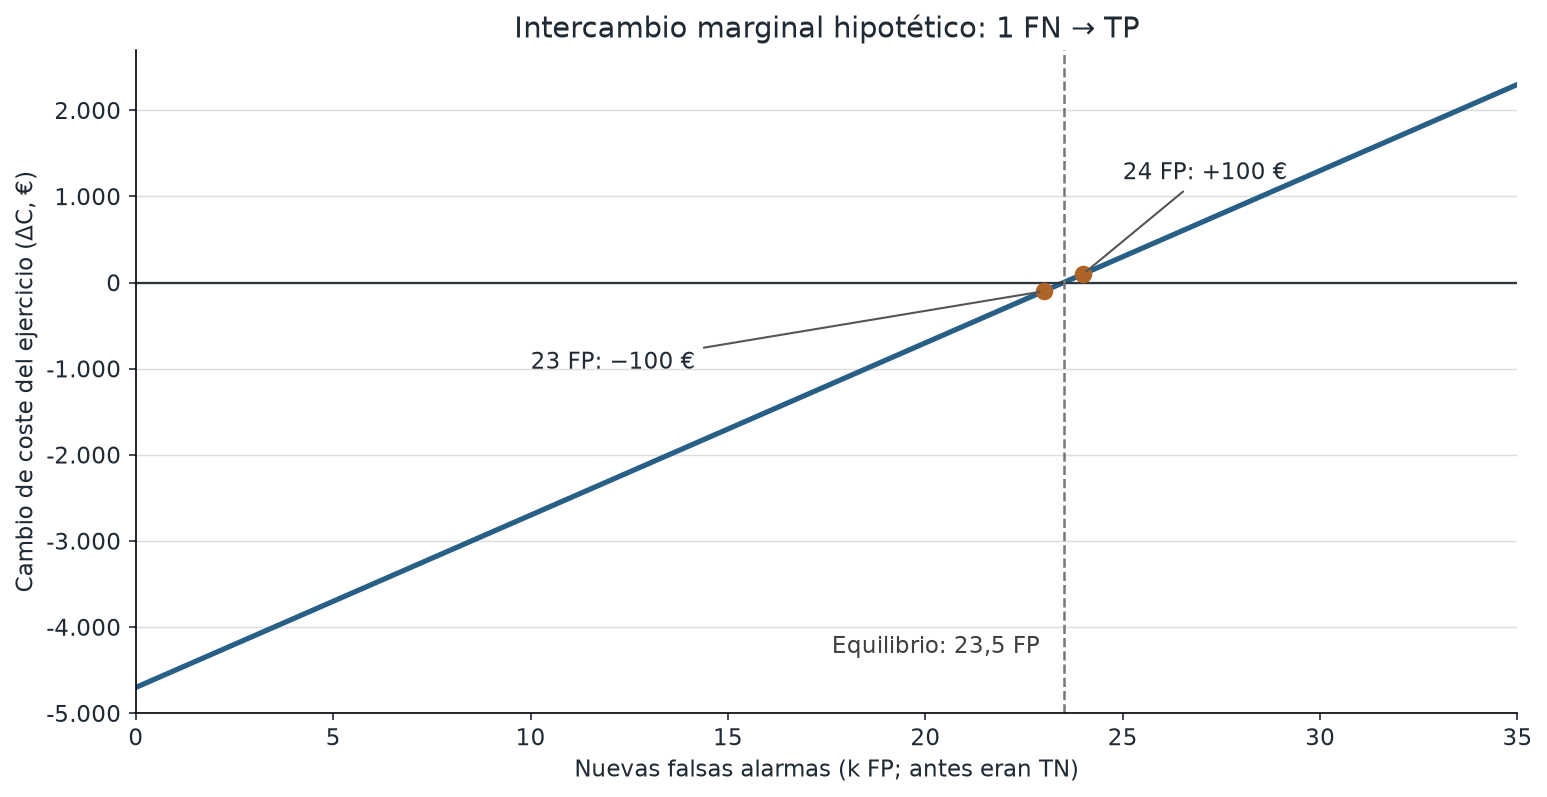

In [6]:
extra_fp = list(range(36))
delta_eur = [marginal_false_alarm * k - marginal_recovery for k in extra_fp]
fig, ax = plt.subplots(figsize=(10.2, 5.2), layout='constrained')
ax.plot(extra_fp, delta_eur, color='#285f87', linewidth=2.5)
ax.axhline(0, color='#30363d', linewidth=1.1)
ax.axvline(float(break_even), color='#777777', linestyle='--', linewidth=1.2)
ax.scatter([23, 24], [-100, 100], color='#ad6426', s=55, zorder=3)
ax.annotate('23 FP: −100 €', (23, -100), xytext=(10, -1000),
            arrowprops={'arrowstyle': '-', 'color': '#555555'})
ax.annotate('24 FP: +100 €', (24, 100), xytext=(25, 1200),
            arrowprops={'arrowstyle': '-', 'color': '#555555'})
ax.text(float(break_even) - 0.6, -4300, 'Equilibrio: 23,5 FP',
        ha='right', color='#404040')
ax.set(title='Intercambio marginal hipotético: 1 FN → TP',
       xlabel='Nuevas falsas alarmas (k FP; antes eran TN)',
       ylabel='Cambio de coste del ejercicio (ΔC, €)',
       xlim=(0, 35), ylim=(-5000, 2700))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: es(x)))
ax.grid(axis='y', color='#dddddd', linewidth=0.7)
ax.set_axisbelow(True)
show_png(fig, '01_marginal_hypothetical.png',
         'Escenario hipotético: delta C igual a menos 4700 más 200 por FP; equilibrio 23,5.')

**Lectura:** un FN recuperado puede compensar hasta 23 FP extra con ahorro
estricto. Con 24 ya se supera ese ahorro. Esto explica la matriz; no aprueba
un nuevo umbral ni una política de mantenimiento.

### Umbral teórico: condiciones, no autorización

Si p fuera una probabilidad **calibrada** de fallo y las dos acciones y sus
costes estuvieran completos, el coste esperado de actuar sería
`300·p + 200·(1−p)`; el de no actuar, `5.000·p`.
Igualarlos da **p óptimo = 200/(5.000−300+200) = 0,040816…**.
El score RF no se declara calibrado aquí. Un coste industrial incompleto,
capacidad limitada o una acción distinta cambia el problema. Este valor
teórico **no es un corte RF aprobado**; se mantienen 0,15/0,70 y el criterio
separado de `risk_threshold` para F2.

In [7]:
theoretical_p = Fraction(costs['fp'] - costs['tn'],
                         costs['fn'] - costs['tp'] + costs['fp'] - costs['tn'])
assert theoretical_p == Fraction(2, 49)
act_cost = theoretical_p * costs['tp'] + (1 - theoretical_p) * costs['fp']
no_act_cost = theoretical_p * costs['fn'] + (1 - theoretical_p) * costs['tn']
assert act_cost == no_act_cost
print(f'p* = {float(theoretical_p):.6f}; solo bajo las condiciones descritas.')

p* = 0.040816; solo bajo las condiciones descritas.


### 2. Políticas archivadas sobre la misma cohorte

Se recalculan los cuatro recuentos a partir de etiquetas y scores ya guardados,
aplicando solo los cortes archivados A, B y C. Se reconcilian con el resumen,
el coste por evento y la identidad algebraica de P fijo; no se llama a las
funciones del estudio original. Las referencias constantes son del mismo ZIP.

In [8]:
def account(rows, fixed_cut=None):
    counts = Counter({'tp': 0, 'fn': 0, 'fp': 0, 'tn': 0})
    event_total = 0
    for row in rows:
        cut = row['threshold'] if fixed_cut is None else fixed_cut
        predicted = row['score'] >= cut
        case = ('tp' if predicted else 'fn') if row['label'] else ('fp' if predicted else 'tn')
        counts[case] += 1
        event_total += costs[case]
    total = sum(counts[key] * costs[key] for key in counts)
    positives = counts['tp'] + counts['fn']
    assert sum(counts.values()) == N and positives == P
    assert counts['tn'] + counts['fp'] == N - P
    assert event_total == total == costs['tp'] * positives + marginal_recovery * counts['fn'] + costs['fp'] * counts['fp']
    return {**counts, 'total': total, 'per_1000': total * 1000 / N,
            'recall': counts['tp'] / P,
            'precision': counts['tp'] / (counts['tp'] + counts['fp']) if counts['tp'] + counts['fp'] else None}

policies = [
    ('RF A · corte inner', 'rf_reference', 'A', None),
    ('RF B · fijo 0,15', 'rf_reference', 'B', 0.15),
    ('RF C · fijo 0,70', 'rf_reference', 'C', 0.70),
    ('always0 · ninguna alerta', 'always0', 'A', None),
    ('always1 · alertar siempre', 'always1', 'A', None),
]
results = []
for label, name, policy, cut in policies:
    metrics = account(archived_rows[name], cut)
    recorded = summary['models'][name][policy]
    assert all(metrics[key] == recorded[key] for key in ('tp', 'fn', 'fp', 'tn'))
    assert recorded['n'] == N and recorded['positives'] == P
    assert metrics['total'] == recorded['cost_total_eur']
    assert math.isclose(metrics['per_1000'], recorded['cost_per_1000'], abs_tol=1e-8)
    assert math.isclose(metrics['recall'], recorded['recall'], abs_tol=1e-12)
    if metrics['precision'] is not None:
        assert math.isclose(metrics['precision'], recorded['precision'], abs_tol=1e-12)
    results.append({'label': label, **metrics})
assert results[3]['total'] == P * costs['fn']
assert results[4]['total'] == P * costs['tp'] + (N - P) * costs['fp']
table(['Política', 'TP', 'FN', 'FP', 'TN', 'Recall', 'Precision', 'Coste (€)', '€/1.000'], [
    [r['label'], r['tp'], r['fn'], r['fp'], r['tn'],
     es(100 * r['recall'], 2) + '%',
     'No definida' if r['precision'] is None else es(100 * r['precision'], 2) + '%',
     es(r['total']), es(r['per_1000'], 2)] for r in results])

Política,TP,FN,FP,TN,Recall,Precision,Coste (€),€/1.000
RF A · corte inner,168,22,95,5315,"88,42%","63,88%",179.400,"32.035,71"
"RF B · fijo 0,15",168,22,63,5347,"88,42%","72,73%",173.000,"30.892,86"
"RF C · fijo 0,70",136,54,0,5410,"71,58%","100,00%",310.800,"55.500,00"
always0 · ninguna alerta,0,190,0,5410,"0,00%",No definida,950.000,"169.642,86"
always1 · alertar siempre,190,0,5410,0,"100,00%","3,39%",1.139.000,"203.392,86"


### Figura 2. ¿Cuánto cuesta cada política en ese escenario?

El denominador es siempre **5.600 registros únicos / 190 positivos**, una vez
por política: outer 0 = 1.867, outer 1 = 1.867, outer 2 = 1.866. Se muestra
**€/1.000 registros** y se conserva la tabla de totales. Las barras descomponen
FN, FP y TP; TN cuesta cero. El orden identifica políticas, no un ranking de
modelos. No hay intervalos de incertidumbre calculados: son recuentos de
desarrollo y costes de escenario, no una estimación financiera poblacional.

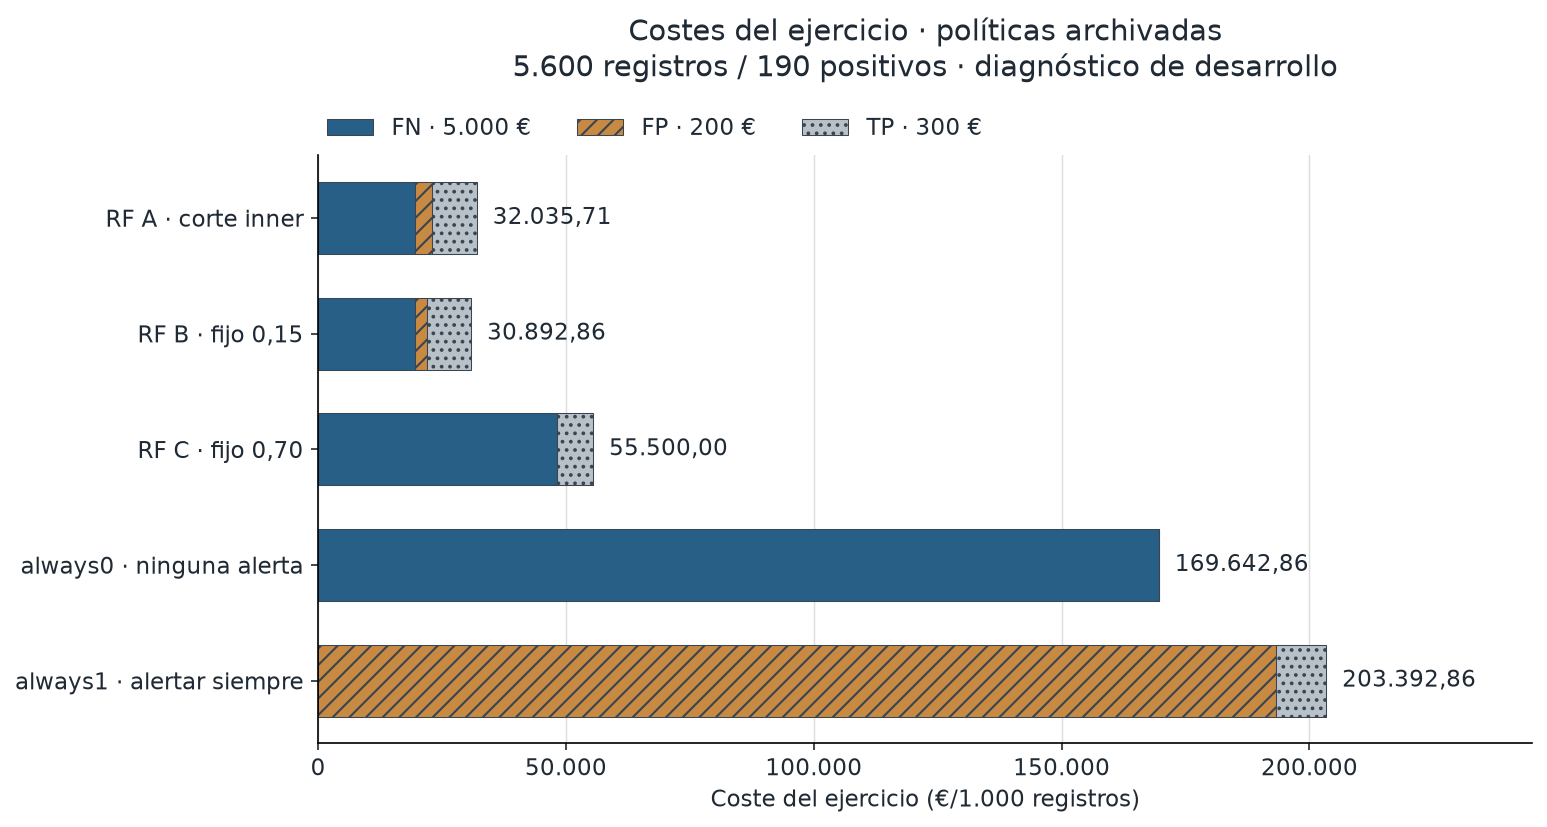

In [9]:
fig, ax = plt.subplots(figsize=(10.2, 5.4), layout='constrained')
positions = list(range(len(results)))
left = [0.0] * len(results)
styles = [('fn', 'FN · 5.000 €', '#285f87', ''),
          ('fp', 'FP · 200 €', '#c88943', '///'),
          ('tp', 'TP · 300 €', '#b8c1c8', '...')]
for case, label, color, hatch in styles:
    width = [r[case] * costs[case] * 1000 / N for r in results]
    ax.barh(positions, width, left=left, color=color, edgecolor='#394550',
            linewidth=0.5, height=0.62, hatch=hatch, label=label)
    left = [a + b for a, b in zip(left, width)]
for pos, r in zip(positions, results):
    ax.text(r['per_1000'] + 3200, pos, es(r['per_1000'], 2), va='center', fontsize=11)
ax.set_yticks(positions, [r['label'] for r in results])
ax.invert_yaxis()
ax.set_xlim(0, 245000)
ax.set_xticks([0, 50000, 100000, 150000, 200000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: es(x)))
ax.set_xlabel('Coste del ejercicio (€/1.000 registros)')
ax.set_title('Costes del ejercicio · políticas archivadas\n'
             '5.600 registros / 190 positivos · diagnóstico de desarrollo', pad=38)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.01), ncols=3,
          frameon=False, borderaxespad=0)
ax.grid(axis='x', color='#dddddd', linewidth=0.7)
ax.set_axisbelow(True)
show_png(fig, '02_archived_policy_costs.png',
         'Costes por 1000 en los mismos 5600 registros: RF A 32035,71; B 30892,86; C 55500; always0 169642,86; always1 203392,86.')

**Lectura de la evidencia:** el RF B conserva 168 TP y 22 FN; A tiene 32 FP más
en esta evaluación outer. Esa diferencia explica 6.400 € entre A y B, pero no
autoriza a sustituir la selección inner por una elección basada en outer.
C elimina los FP en esta cohorte y deja 54 FN; su coste es 310.800 €.
El 100 % de precision de C describe solo esos 136 avisos positivos.
En `always0` la precision no está definida porque no hay avisos, aunque el
resumen de origen use la convención numérica cero.

In [10]:
a, b, c, no_alert, all_alert = results
assert a['tp'] == b['tp'] and a['fn'] == b['fn']
assert a['total'] - b['total'] == (a['fp'] - b['fp']) * costs['fp'] == 6400
saving = no_alert['total'] - b['total']
assert saving == summary['models']['rf_reference']['B']['hypothetical_saving_vs_no_alert_eur']
print(f"RF B frente a always0: diferencia hipotética {es(saving)} € ({es(100 * saving / no_alert['total'], 2)}%).")
print('Alcance: una cohorte de desarrollo, sin anualizar ni probar ahorro industrial.')
print('Comprobaciones de hashes, cohorte, folds, recuentos y aritmética: correctas.')

RF B frente a always0: diferencia hipotética 777.000 € (81,79%).
Alcance: una cohorte de desarrollo, sin anualizar ni probar ahorro industrial.
Comprobaciones de hashes, cohorte, folds, recuentos y aritmética: correctas.


## Qué explicar y cómo reproducir

Para la presentación, usar la matriz y la **figura 1** para justificar el ahorro
marginal; después la **figura 2** y su tabla para explicar las decisiones del RF.
Conservar junto al gráfico la cohorte, el denominador y la advertencia de que
son costes hipotéticos de desarrollo. Los PNG nativos pueden incorporarse a
la presentación; este encargo no modifica la presentación ni la publica.

**Resultado:** el coste del TP cambia 25 a 23,5 como relación marginal. En la
cohorte archivada, RF B cuesta 173.000 € frente a 950.000 € de `always0`.
**Límite:** ningún mínimo outer demuestra un ganador operativo ni ahorro real;
el escenario docente es posterior al experimento primario. La aceptación
docente, una prueba final independiente y la validación industrial quedan fuera.

**Lectura:** las figuras se preparan para unos 960 px de ancho; ampliar el PNG
si el visor reduce sus etiquetas. Las tablas mantienen los números completos y
permiten desplazamiento horizontal en visores estrechos.

**Reproducción:** seleccionar un kernel con las dependencias indicadas y ejecutar
todas las celdas de arriba abajo desde el repositorio. No hacen falta modelos,
servicios, credenciales ni descargar datos. `COST_NOTEBOOK_OUTPUT_DIR` es opcional
y solo controla la copia de los dos PNG; los resultados quedan dentro del
`.ipynb` aunque no se defina. No hay instalaciones en las celdas.

La evidencia de esta ejecución, las versiones, los comandos, los hashes de
salida y la revisión visual están en
[COST_NOTEBOOK_20261023.md](../docs/evidence/COST_NOTEBOOK_20261023.md).